# Scene classification (image-level labels)

We train a small CNN to assign **one scene class per image** — the most
important area represented. Seven classes are derived from the scene
vocabulary:

| class | scenes |
|---|---|
| cropland | fields, **forest_fields** |
| urban | urban, **urban_fringe** |
| coastal | coastal |
| mountain | mountain |
| arid | arid |
| forest | forest, wilderness |
| pasture | pasture |

The **ambiguous** boundary scenes are intentionally kept: `forest_fields` is
labelled *cropland* (farmland dominates) and `urban_fringe` is labelled *urban*
(settlement dominates). Each image still gets exactly one label.

The model is a small CNN with global average pooling, trained with
cross-entropy on Apple **MPS**. Metrics: accuracy, per-class accuracy and a
confusion matrix.


## Learning objectives

By the end of this notebook you will be able to:

- turn rendered scenes into an **image-level classification** dataset (one label per image);
- build a small CNN with **global average pooling** as a classifier;
- train it with **cross-entropy** and read a **confusion matrix**;
- explain why the boundary scenes (`forest_fields`, `urban_fringe`) are ambiguous.

### Exercises

1. `forest_fields` is labelled *cropland* and `urban_fringe` is labelled *urban*.
   Relabel them the other way and describe how the confusion matrix changes.
2. Add a horizontal flip to the training loop. Does validation accuracy improve,
   and why?

**What to expect.** (1) Only the two boundary rows move: the confusion
concentrates between the swapped classes and overall accuracy barely changes,
because the scenes genuinely mix both. (2) Scene texture is not
orientation-specific, so a flip usually gives a small accuracy gain and a
smoother validation curve.


### Key terms

- **logits** — the raw, unnormalised score the network outputs per class.
- **softmax** — turns logits into a probability distribution (sums to 1).
- **cross-entropy** — the loss that rewards high probability on the true class,
  $-\log p(y)$.
- **confusion matrix** — counts of (true class, predicted class); the diagonal is
  correct and the off-diagonal is where errors concentrate.
- **global average pooling** — averaging feature maps over space into one vector.
- **boundary scene** — a render mixing two classes (`forest_fields`,
  `urban_fringe`), whose single label is a convention.

In [1]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
print("torch", torch.__version__, "| device", DEVICE)
if DEVICE == "cpu":
    print("MPS not available: training will be slower (CPU fallback).")


torch 2.14.0 | device mps


## Dataset (balanced over classes)

In [2]:
from mlpsyn.scene import generate_scene

SIZE = 64
N_PER_CLASS = 72
N_VAL_PER_CLASS = 16
N_TEST_PER_CLASS = 12

# Scene type -> image-level class. The boundary scenes are ambiguous and are
# assigned the dominant area's class.
SCENE_TO_CLASS = {
    "fields": "cropland",
    "forest_fields": "cropland",
    "urban": "urban",
    "urban_fringe": "urban",
    "coastal": "coastal",
    "mountain": "mountain",
    "arid": "arid",
    "forest": "forest",
    "wilderness": "forest",
    "pasture": "pasture",
}
CLASSES = sorted(set(SCENE_TO_CLASS.values()))
CLASS_INDEX = {name: idx for idx, name in enumerate(CLASSES)}
print("classes:", CLASSES)


def make_data(n_per_class, size, seed=0):
    """Balanced dataset: sample scenes until every class has n_per_class images."""
    rng = np.random.default_rng(seed)
    options = list(SCENE_TO_CLASS.items())
    images, labels = [], []
    counts = dict.fromkeys(CLASSES, 0)
    while min(counts.values()) < n_per_class:
        scene_name, class_name = options[int(rng.integers(len(options)))]
        if counts[class_name] >= n_per_class:
            continue
        scene_seed = int(rng.integers(10_000))
        images.append(generate_scene(scene_name, size=size, seed=scene_seed).image)
        labels.append(CLASS_INDEX[class_name])
        counts[class_name] += 1
    image_tensor = torch.from_numpy(
        np.stack(images).astype(np.float32).transpose(0, 3, 1, 2) / 255.0
    )
    return image_tensor, torch.tensor(labels)


started = time.time()
images, labels = make_data(N_PER_CLASS, SIZE)
# Three disjoint, class-balanced splits: fit / model selection / final report.
train_images, val_images, test_images = [], [], []
train_labels, val_labels, test_labels = [], [], []
cut = N_VAL_PER_CLASS + N_TEST_PER_CLASS
for class_id in range(len(CLASSES)):
    class_indices = (labels == class_id).nonzero().flatten()
    train_images.append(images[class_indices[:-cut]])
    train_labels.append(labels[class_indices[:-cut]])
    val_images.append(images[class_indices[-cut:-N_TEST_PER_CLASS]])
    val_labels.append(labels[class_indices[-cut:-N_TEST_PER_CLASS]])
    test_images.append(images[class_indices[-N_TEST_PER_CLASS:]])
    test_labels.append(labels[class_indices[-N_TEST_PER_CLASS:]])
train_images, train_labels = torch.cat(train_images), torch.cat(train_labels)
val_images, val_labels = torch.cat(val_images), torch.cat(val_labels)
test_images, test_labels = torch.cat(test_images), torch.cat(test_labels)
print("train", tuple(train_images.shape), "val", tuple(val_images.shape),
      "test", tuple(test_images.shape))
print("generated in", round(time.time() - started, 1), "s")


classes: ['arid', 'coastal', 'cropland', 'forest', 'mountain', 'pasture', 'urban']


train (308, 3, 64, 64) val (112, 3, 64, 64) test (84, 3, 64, 64)
generated in 38.9 s


## Prediction and target spaces, loss and metric

- **Prediction** `logits` ∈ ℝ^{B×7}; probabilities `softmax(logits)`.
- **Target** `y` ∈ {0,…,6}^B (one class index per image).

**Loss** — categorical cross-entropy:

$$\mathcal{L} = -\frac{1}{B}\sum_{b=1}^{B}\log \mathrm{softmax}(z_b)[y_b]$$

**Metrics**
- accuracy $= \frac{1}{B}\sum_b \mathbf{1}[\arg\max_c z_b^c = y_b]$
- per-class accuracy and the confusion matrix $C_{ij}$ = #(true $i$, predicted $j$).


In [3]:
# Loss and metric values on toy logits / labels (no model yet).
example_logits = torch.tensor(
    [
        [3.0, 1.0, 0.0, -1.0, 0.0, 0.0, 0.0],
        [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0],
        [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0],
    ]
)
example_labels = torch.tensor([0, 3, 6])
print("cross-entropy:", round(float(F.cross_entropy(example_logits, example_labels)), 3))
manual_loss = -F.log_softmax(example_logits, dim=1).gather(1, example_labels[:, None])[:, 0].mean()
print("manual CE:    ", round(float(manual_loss), 3))
predictions = example_logits.argmax(1)
print("predictions:", predictions.tolist(), "| accuracy:", round(float((predictions == example_labels).float().mean()), 3))


cross-entropy: 0.687
manual CE:     0.687
predictions: [0, 3, 6] | accuracy: 1.0


## Model

In [4]:
class SceneCNN(nn.Module):
    """Small CNN with global average pooling for image-level scene labels."""

    def __init__(self, n_classes, base=24):
        super().__init__()

        def block(in_channels, out_channels, stride=2):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.features = nn.Sequential(
            block(3, base), block(base, base * 2), block(base * 2, base * 4)
        )
        self.head = nn.Linear(base * 4, n_classes)

    def forward(self, image_batch):
        pooled_features = self.features(image_batch).mean(dim=(2, 3))
        return self.head(pooled_features)


model = SceneCNN(len(CLASSES)).to(DEVICE)
n_parameters = sum(p.numel() for p in model.parameters())
print(f"{n_parameters/1e3:.1f} k parameters")


162.7 k parameters


## Training loop

In [5]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
EPOCHS, BATCH_SIZE = 30, 32
train_images_device = train_images.to(DEVICE)
train_labels_device = train_labels.to(DEVICE)
history = []


def evaluate(images_split, labels_split):
    """Validation loss, accuracy, confusion matrix and predictions for one split."""
    model.eval()
    with torch.no_grad():
        logits = model(images_split.to(DEVICE))
        split_loss = F.cross_entropy(logits, labels_split.to(DEVICE)).item()
        predictions = logits.argmax(1).cpu()
    accuracy = (predictions == labels_split).float().mean().item()
    confusion = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    for true_label, predicted_label in zip(labels_split.tolist(), predictions.tolist()):
        confusion[true_label, predicted_label] += 1
    return split_loss, accuracy, confusion, predictions


started = time.time()
for epoch in range(EPOCHS):
    model.train()
    permutation = torch.randperm(len(train_images_device), device=DEVICE)
    running_loss = 0.0
    # One cross-entropy step per batch; log validation loss/accuracy every 2 epochs.
    for start in range(0, len(train_images_device), BATCH_SIZE):
        batch_indices = permutation[start : start + BATCH_SIZE]
        optimizer.zero_grad()
        loss = F.cross_entropy(
            model(train_images_device[batch_indices]), train_labels_device[batch_indices]
        )
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(batch_indices)
    if epoch % 2 == 1 or epoch == EPOCHS - 1:
        validation_loss, accuracy, _, _ = evaluate(val_images, val_labels)
        history.append((epoch, running_loss / len(train_images_device), validation_loss, accuracy))
        print(
            f"epoch {epoch:2d} | loss {running_loss/len(train_images_device):.3f}"
            f" | val loss {validation_loss:.3f} | val acc {accuracy:.3f}"
            f" | {time.time()-started:.0f}s"
        )
print("training time:", round(time.time() - started, 1), "s")


epoch  1 | loss 0.458 | val loss 2.200 | val acc 0.161 | 1s


epoch  3 | loss 0.230 | val loss 1.043 | val acc 0.670 | 2s


epoch  5 | loss 0.146 | val loss 0.316 | val acc 0.911 | 2s


epoch  7 | loss 0.094 | val loss 0.042 | val acc 0.991 | 2s


epoch  9 | loss 0.061 | val loss 0.041 | val acc 1.000 | 3s


epoch 11 | loss 0.039 | val loss 0.031 | val acc 1.000 | 4s


... (5 outputs left out)

epoch 23 | loss 0.011 | val loss 0.006 | val acc 1.000 | 5s


epoch 25 | loss 0.012 | val loss 0.005 | val acc 1.000 | 6s


epoch 27 | loss 0.102 | val loss 0.537 | val acc 0.821 | 6s


epoch 29 | loss 0.055 | val loss 0.036 | val acc 1.000 | 6s
training time: 6.3 s


## Evaluation

We report validation and test accuracy, per-class accuracy, the confusion
matrix, the **training and validation loss curves** (plus validation
accuracy) and the **majority-class baseline** (always predicting the most
common training class). The baseline is the score to beat: with seven
balanced classes it sits near 1/7, so the model's accuracy is only
meaningful above it. Watching the two loss curves together shows whether
the model is still learning or starting to overfit.

validation accuracy 1.000
test accuracy       1.000   <- reported once, never used for tuning
per-class accuracy:
  arid      1.00  (16/16)
  coastal   1.00  (16/16)
  cropland  1.00  (16/16)
  forest    1.00  (16/16)
  mountain  1.00  (16/16)
  pasture   1.00  (16/16)
  urban     1.00  (16/16)
majority-class baseline accuracy 0.143 (always predict 'arid')


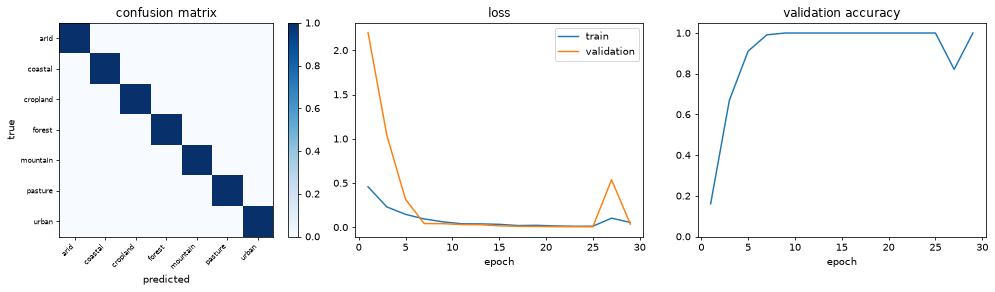

In [6]:
validation_loss, accuracy, confusion, predictions = evaluate(val_images, val_labels)
test_loss, test_accuracy, test_confusion, test_predictions = evaluate(test_images, test_labels)
print(f"validation accuracy {accuracy:.3f}")
print(f"test accuracy       {test_accuracy:.3f}   <- reported once, never used for tuning")
print("per-class accuracy:")
for class_id, class_name in enumerate(CLASSES):
    total = confusion[class_id].sum()
    print(f"  {class_name:9s} {confusion[class_id, class_id] / total:.2f}  ({confusion[class_id, class_id]}/{total})")

# Trivial baseline: always predict the most frequent training class. A score is
# only meaningful relative to what "doing nothing" already achieves.
majority_class = int(np.bincount(train_labels.numpy()).argmax())
baseline_accuracy = (val_labels == majority_class).float().mean().item()
print(f"majority-class baseline accuracy {baseline_accuracy:.3f} "
      f"(always predict '{CLASSES[majority_class]}')")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=70)
confusion_normalized = confusion / confusion.sum(axis=1, keepdims=True)
image = axes[0].imshow(confusion_normalized, cmap="Blues", vmin=0, vmax=1)
axes[0].set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right", fontsize=7)
axes[0].set_yticks(range(len(CLASSES)), CLASSES, fontsize=7)
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true")
axes[0].set_title("confusion matrix")
fig.colorbar(image, ax=axes[0], fraction=0.046)
epochs = [row[0] for row in history]
axes[1].plot(epochs, [row[1] for row in history], label="train")
axes[1].plot(epochs, [row[2] for row in history], label="validation")
axes[1].set_title("loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
axes[2].plot(epochs, [row[3] for row in history]); axes[2].set_title("validation accuracy")
axes[2].set_xlabel("epoch"); axes[2].set_ylim(0, 1.05)
plt.tight_layout()
plt.show()


## How noisy is a single number?

A reported accuracy is one draw from a random process: the weight
initialisation, the batch order and the augmentation are all seeded. Re-train
the same model with three different seeds on a short schedule and look at the
spread. Differences smaller than this spread are **noise**, not signal — a
lesson that applies to every model in these notebooks.

In [7]:
def train_with_seed(seed, epochs=15):
    """Train a fresh classifier with one seed; return validation accuracy."""
    torch.manual_seed(seed)
    candidate = SceneCNN(len(CLASSES)).to(DEVICE)
    candidate_optimizer = torch.optim.AdamW(candidate.parameters(), lr=1e-3)
    for _ in range(epochs):
        candidate.train()
        permutation = torch.randperm(len(train_images_device), device=DEVICE)
        for start in range(0, len(train_images_device), BATCH_SIZE):
            batch_indices = permutation[start : start + BATCH_SIZE]
            candidate_optimizer.zero_grad()
            loss = F.cross_entropy(
                candidate(train_images_device[batch_indices]),
                train_labels_device[batch_indices])
            loss.backward()
            candidate_optimizer.step()
    candidate.eval()
    with torch.no_grad():
        predictions = candidate(val_images.to(DEVICE)).argmax(1).cpu()
    return (predictions == val_labels).float().mean().item()


seed_accuracies = [train_with_seed(seed) for seed in (0, 1, 2)]
print("validation accuracy over 3 seeds:", [f"{value:.3f}" for value in seed_accuracies])
print(f"mean {np.mean(seed_accuracies):.3f} | std {np.std(seed_accuracies):.3f}")


validation accuracy over 3 seeds: ['0.857', '1.000', '1.000']
mean 0.952 | std 0.067


## Example predictions

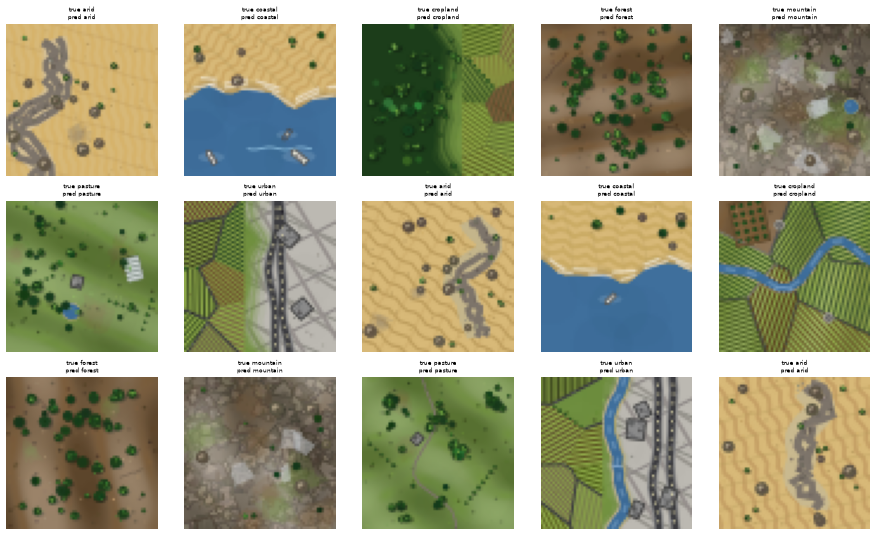

In [8]:
# Qualitative check: three rows of five validation scenes, sampled round-robin
# across the classes so the grid is not dominated by one label.
per_class = {
    class_id: (val_labels == class_id).nonzero().flatten().tolist()
    for class_id in range(len(CLASSES))
}
sample_indices, class_cursor = [], 0
while len(sample_indices) < 15:
    class_id = class_cursor % len(CLASSES)
    if per_class[class_id]:
        sample_indices.append(per_class[class_id].pop(0))
    class_cursor += 1

fig, axes = plt.subplots(3, 5, figsize=(15, 9), dpi=60)
for sample_idx, ax in zip(sample_indices, axes.ravel()):
    ax.imshow(val_images[sample_idx].permute(1, 2, 0))
    ax.set_title(
        f"true {CLASSES[val_labels[sample_idx]]}\npred {CLASSES[predictions[sample_idx]]}",
        fontsize=7,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()


### Evaluation protocol and failure gallery

We keep three disjoint splits: **train** (fit the weights), **validation**
(model selection / the epoch we keep) and **test** (reported once, never used
for any decision). Reporting a held-out test score is what makes the number
trustworthy. Below are the validation scenes the classifier got wrong.

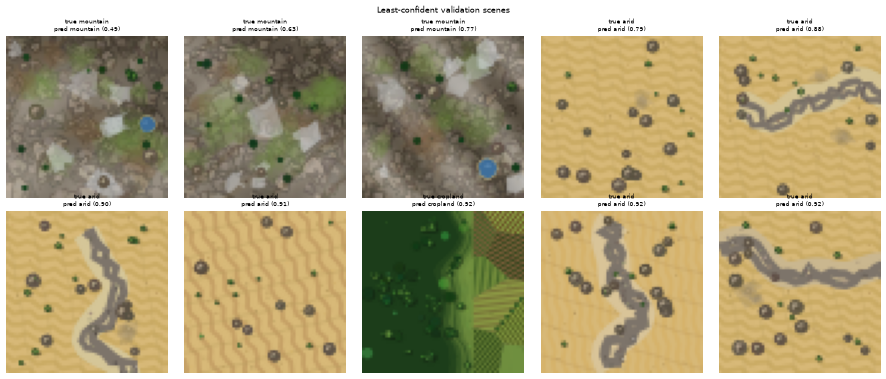

In [9]:
# "Where does the model hesitate?" gallery: the ten least-confident validation
# predictions (lowest max softmax), with the true and predicted label.
model.eval()
with torch.no_grad():
    probabilities = torch.softmax(model(val_images.to(DEVICE)), dim=1).cpu()
confidence = probabilities.max(1).values
order = confidence.argsort().flatten().tolist()

fig, axes = plt.subplots(2, 5, figsize=(15, 6.4), dpi=60)
for ax, sample_idx in zip(axes.ravel(), order[:10]):
    ax.imshow(val_images[sample_idx].permute(1, 2, 0))
    ax.set_title(
        f"true {CLASSES[val_labels[sample_idx]]}\n"
        f"pred {CLASSES[predictions[sample_idx]]} ({confidence[sample_idx]:.2f})",
        fontsize=7,
    )
    ax.axis("off")
plt.suptitle("Least-confident validation scenes", fontsize=10)
plt.tight_layout()
plt.show()


This notebook classifies **64x64** scene thumbnails. At that size, boundary
scenes (`forest_fields`, `urban_fringe`) genuinely share texture and layout, so
some confusion is intrinsic to the task, not a modelling failure.

### Interpreting these numbers

The scores above are measured on **deliberately hard** imagery, not a clean
benchmark, and that is the point of a synthetic dataset:

- **High accuracy on clean images can mislead.** A classifier that only sees
  pristine renders can look near-perfect and still fail on the first hazy or
  blurry acquisition; a slightly lower number on degraded data is the more
  honest summary of real-world performance.
- **Resolution bounds what can be recovered.** At `64 x 64` a whole city block is
  only a few pixels, so fine distinctions between scene types are lost.
- **Some "errors" are label ambiguity.** `forest_fields` is counted as cropland
  and `urban_fringe` as urban: a mixed scene has no single correct label.
- **Accuracy hides which classes fail.** Read it together with the confusion
  matrix and the least-confident gallery, never as a single number.

The takeaway is not "the model is bad", but "these metrics quantify **robustness
under realistic conditions**"; improving them means investing in resolution or
priors, not just a bigger network.
